# Codex diagnostic: NOAA OLR equivalent depths versus Gaussian background

**Agent-authored exploratory analysis.** This notebook is deliberately separate from the project's established analysis notebooks. All analysis and plotting code is defined here; it makes no changes to `src/` and writes no figure files. Figures appear only as notebook outputs.

**Question.** Do fitted equivalent-depth distributions of observed NOAA OLR wave events differ from those of events detected in matched stationary Gaussian background records? The comparison is made separately for Kelvin, MRG, n0EIG, n1ERW, and n1WIG. These figures are descriptive; they do not establish the significance of a preferred depth.


## Inputs and choices

- **Observations:** 1990-01-01 through 2010-12-31 NOAA OLR, with 1.5-standard-deviation Hilbert-envelope detection and raw sinusoid fitting on active event pixels.
- **Background:** 1,000 held-out 21-year Gaussian realizations per wave, drawn from the saved WK99-style 1-2-1 smoothed spectrum. Every background event passed through the same detector, fit, and dispersion inversion. `catalog_index.1000-2000.csv` is the completed audit.
- **Screened selection:** `keep_for_histogram == True`, incorporating fit success, R², search-edge, spatial-cycle, temporal-cycle, and dispersion-validity screens.
- **Relaxed selection:** all events with a successful fit and finite, positive, dispersion-valid `h_eff_m`. No R², search-edge, spatial-cycle, or temporal-cycle cutoff is applied. Events without a valid fitted depth cannot appear on a depth axis.
- **Binning:** the overview uses 50 equal-width bins in `log10(h_eff / m)` from 0.5 to 10,000 m. The linear detail uses 1 m bins spanning 1–200 m (edges 1, 2, …, 200 m). Events outside either display range remain in each selection's denominator.
- **Comparison:** each curve is a fraction of that record's selected events per decade of depth. The orange band is the **pointwise** 2.5th–97.5th percentile of the 1,000 full-record background densities. It is not a simultaneous confidence band or a multiple-testing-adjusted significance test. No 1% or 5% peak-amplitude threshold is imposed: this analysis compares the full detected-event populations.

Inputs must be available through the project's `data/` directory. Run from the project root or `notebooks/` with the `cmip6_equiv_depth_distributions` Python kernel on Levante.


In [1]:
%matplotlib inline

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "data").is_dir():
    raise FileNotFoundError("Run from the project root or notebooks/ with data/ configured")
DATA_DIR = PROJECT_ROOT / "data"
NULL_RUN = (DATA_DIR / "wave_significance" / "gaussian_calibration_wk99_121"
            / "NOAA_OLR.observations.not_applicable.1990-2010.b898b1ae4307")
CATALOG_DIR = NULL_RUN / "component_fit_catalogs"
WAVES = ("Kelvin", "MRG", "n0EIG", "n1ERW", "n1WIG")
SELECTIONS = {"screened": "Quality-screened", "relaxed": "All valid-depth fits"}
EDGES_M = np.geomspace(0.5, 10_000.0, 51)
LOG_WIDTH = np.diff(np.log10(EDGES_M))
LINEAR_EDGES_M = np.arange(1.0, 201.0, 1.0)  # 1 m bins from 1 through 200 m.

with (NULL_RUN / "manifest.json").open() as handle:
    manifest = json.load(handle)
if manifest["status"] != "complete" or manifest["configuration"]["n_validation"] != 1000:
    raise RuntimeError("The expected completed NOAA null ensemble is unavailable")
index = pd.read_csv(CATALOG_DIR / "catalog_index.1000-2000.csv")
if (len(index) != 5000 or index.duplicated(["wave_type", "realization"]).any()
        or set(index.wave_type) != set(WAVES)):
    raise RuntimeError("Expected exactly 1,000 audited null catalogs per wave")

observed_catalogs = {}
for wave in WAVES:
    matches = [p for p in DATA_DIR.glob(
        f"NOAA_OLR.{wave}.19900101-20101231.*.ds1p5.component.*.csv")
        if ".pilot" not in p.name]
    if len(matches) != 1:
        raise RuntimeError(f"Expected one full observed component catalog for {wave}; found {matches}")
    path = matches[0]
    with path.with_suffix(".json").open() as handle:
        metadata = json.load(handle)
    config = metadata["configuration"]
    if (metadata["status"] != "complete" or config["fit_support"] != "component"
            or config["detection"]["detection_sigma"] != 1.5
            or config["wave_type"] != wave or config["max_events"] is not None):
        raise RuntimeError(f"Unexpected observed catalog provenance: {path}")
    observed_catalogs[wave] = (path, metadata)
print("Inputs: five observed catalogs and", len(index), "audited null catalogs")


Inputs: five observed catalogs and 5000 audited null catalogs


In [2]:
def selected_depths(path):
    """Return both depth selections and the candidate count from one catalog."""
    frame = pd.read_csv(
        path, usecols=["h_eff_m", "keep_for_histogram", "fit_success", "dispersion_valid"],
        dtype={"h_eff_m": "float64", "keep_for_histogram": "boolean",
               "fit_success": "boolean", "dispersion_valid": "boolean"},
    )
    depth = frame.h_eff_m.to_numpy(dtype=float)
    valid_depth = np.isfinite(depth) & (depth > 0)
    screened = frame.keep_for_histogram.fillna(False).to_numpy(dtype=bool)
    relaxed = (frame.fit_success.fillna(False).to_numpy(dtype=bool)
               & frame.dispersion_valid.fillna(False).to_numpy(dtype=bool)
               & valid_depth)
    if np.any(screened & ~relaxed):
        raise RuntimeError(f"Quality-screened events lack a valid depth: {path}")
    return {"screened": depth[screened], "relaxed": depth[relaxed]}, len(frame)


results = {}
summary_rows = []
for wave in WAVES:
    observed_path, observed_metadata = observed_catalogs[wave]
    observed, observed_candidates = selected_depths(observed_path)
    if observed_candidates != observed_metadata["catalog_candidates"]:
        raise RuntimeError(f"Observed row count differs from provenance: {wave}")
    records = index.loc[index.wave_type.eq(wave)].sort_values("realization")
    if records.realization.tolist() != list(range(1000, 2000)):
        raise RuntimeError(f"Missing or unordered null realizations for {wave}")
    null_hist = {key: np.empty((1000, len(LOG_WIDTH)), dtype=np.int32)
                 for key in SELECTIONS}
    null_linear_hist = {key: np.empty((1000, len(LINEAR_EDGES_M) - 1), dtype=np.int32)
                        for key in SELECTIONS}
    null_n = {key: np.empty(1000, dtype=np.int32) for key in SELECTIONS}
    for j, row in enumerate(records.itertuples(index=False)):
        depths, candidates = selected_depths(PROJECT_ROOT / row.catalog)
        if candidates != row.candidates or len(depths["screened"]) != row.keep_for_histogram:
            raise RuntimeError(f"Null catalog differs from the audited index: {row.catalog}")
        for key in SELECTIONS:
            null_n[key][j] = len(depths[key])
            null_hist[key][j] = np.histogram(depths[key], bins=EDGES_M)[0]
            null_linear_hist[key][j] = np.histogram(depths[key], bins=LINEAR_EDGES_M)[0]
    results[wave] = {}
    for key in SELECTIONS:
        observed_hist = np.histogram(observed[key], bins=EDGES_M)[0]
        observed_linear_hist = np.histogram(observed[key], bins=LINEAR_EDGES_M)[0]
        observed_n = len(observed[key])
        results[wave][key] = dict(observed_hist=observed_hist, observed_n=observed_n,
                                  null_hist=null_hist[key], null_n=null_n[key],
                                  observed_linear_hist=observed_linear_hist,
                                  null_linear_hist=null_linear_hist[key])
        summary_rows.append(dict(
            wave_type=wave, selection=key, observed_candidates=observed_candidates,
            observed_depth_events=observed_n,
            null_median_depth_events=int(np.median(null_n[key])),
            null_95pct_record_range=(int(np.quantile(null_n[key], 0.025)),
                                      int(np.quantile(null_n[key], 0.975))),
            observed_outside_plot_pct=100 * (observed_n - observed_hist.sum()) / observed_n,
            null_outside_plot_pct=100 * (null_n[key].sum() - null_hist[key].sum())
                                  / null_n[key].sum(),
        ))
    print(f"{wave}: observed {observed_candidates} candidates; 1,000 null records processed")

summary = pd.DataFrame(summary_rows)
display(summary.round({"observed_outside_plot_pct": 2, "null_outside_plot_pct": 2}))


Kelvin: observed 2897 candidates; 1,000 null records processed


MRG: observed 2964 candidates; 1,000 null records processed


n0EIG: observed 3660 candidates; 1,000 null records processed


n1ERW: observed 1029 candidates; 1,000 null records processed


n1WIG: observed 3836 candidates; 1,000 null records processed


,wave_type,selection,observed_candidates,observed_depth_events,null_median_depth_events,null_95pct_record_range,observed_outside_plot_pct,null_outside_plot_pct
0,Kelvin,screened,2897,767,1098,"(1052, 1144)",0.00,0.00
1,Kelvin,relaxed,2897,2897,4263,"(4165, 4362)",0.00,0.00
2,MRG,screened,2964,806,1063,"(1018, 1109)",0.50,0.21
3,MRG,relaxed,2964,2847,3220,"(3133, 3303)",2.18,1.77
4,n0EIG,screened,3660,1409,1880,"(1818, 1940)",0.00,0.00
5,n0EIG,relaxed,3660,3660,4054,"(3969, 4143)",0.00,0.00
6,n1ERW,screened,1029,215,388,"(362, 416)",0.00,0.00
7,n1ERW,relaxed,1029,1029,1392,"(1337, 1448)",0.00,0.00
8,n1WIG,screened,3836,2036,2446,"(2377, 2519)",0.00,0.00
9,n1WIG,relaxed,3836,3836,4433,"(4343, 4533)",0.00,0.00


## Quality-screened equivalent-depth distributions

These five figures use the existing `keep_for_histogram` rule. The blue curve is the single observed 21-year record; the orange curve and band summarize 1,000 independent 21-year background records. Density is normalized within each record by **all** selected depths, including rare values outside the displayed x range.


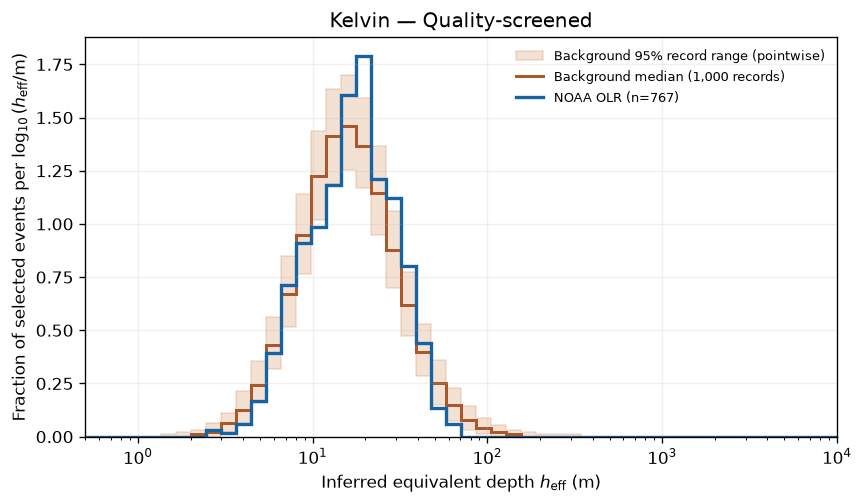

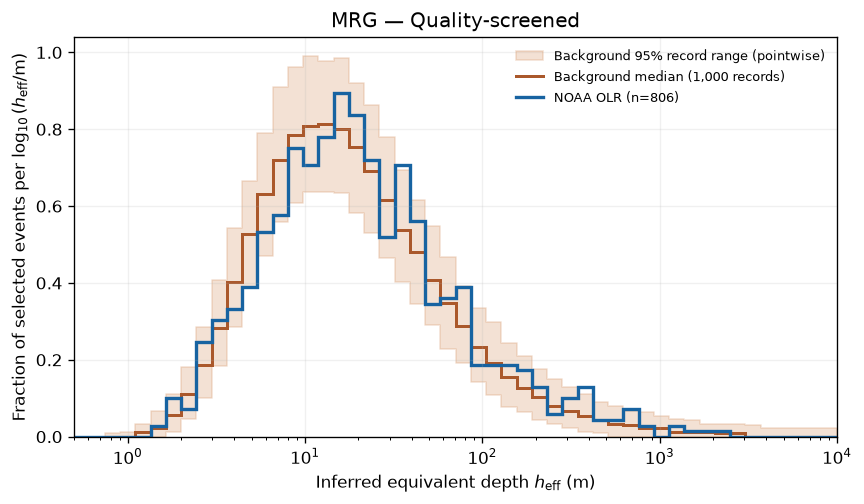

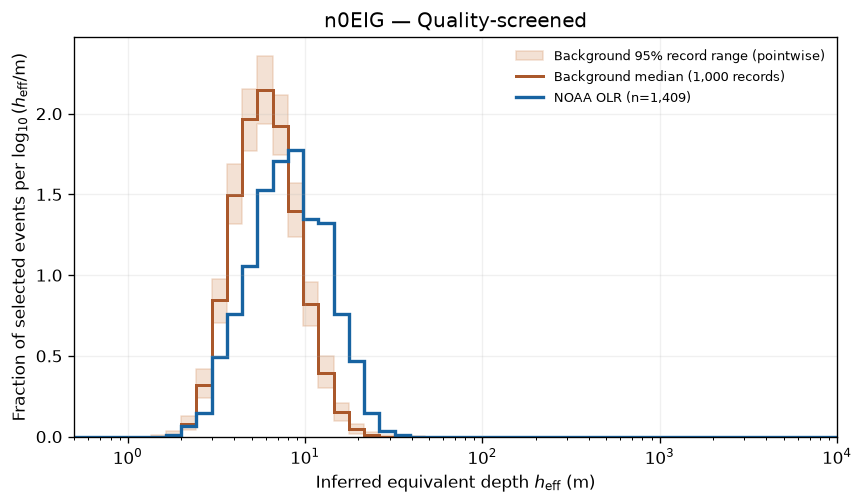

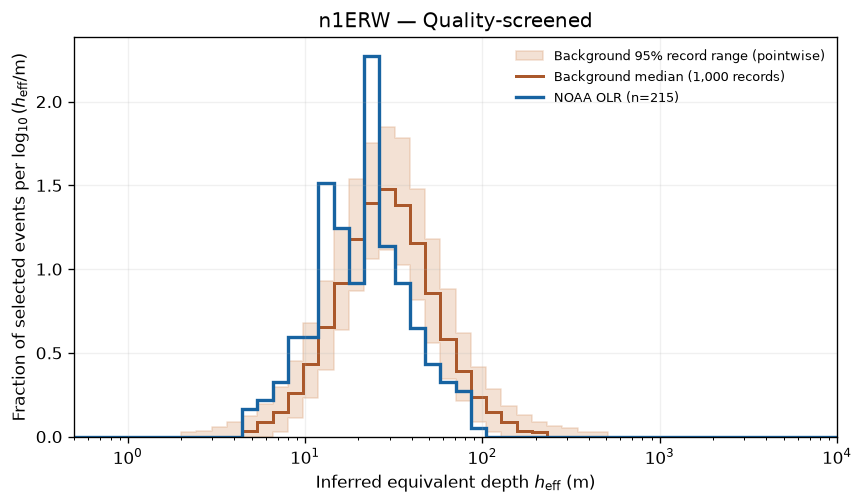

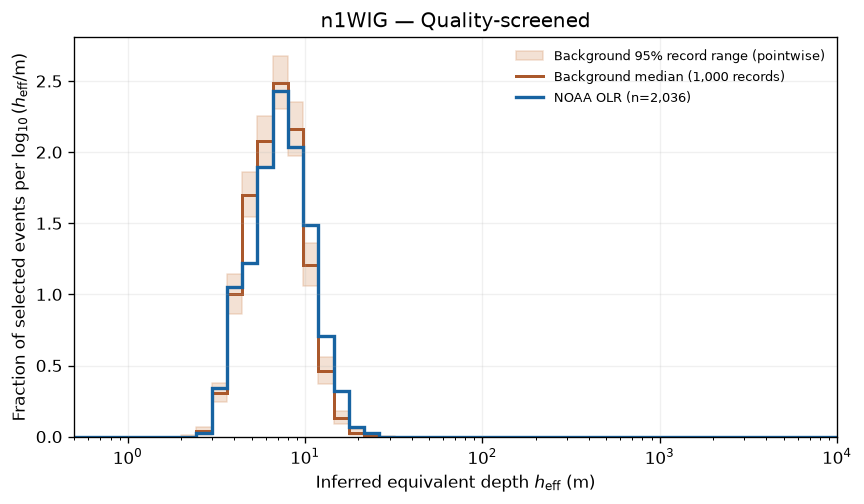

In [3]:
def plot_depth_distribution(wave, selection):
    """Display one standalone observed-versus-null depth-density panel; save no file."""
    result = results[wave][selection]
    observed_n = result["observed_n"]
    null_n = result["null_n"]
    if observed_n == 0 or np.any(null_n == 0):
        raise RuntimeError(f"No selected events for {wave}/{selection}")
    observed_density = result["observed_hist"] / observed_n / LOG_WIDTH
    null_density = result["null_hist"] / null_n[:, None] / LOG_WIDTH[None, :]
    lower, median, upper = np.quantile(null_density, [0.025, 0.5, 0.975], axis=0)

    fig, ax = plt.subplots(figsize=(7.3, 4.3), dpi=120)
    ax.fill_between(EDGES_M, np.r_[lower, lower[-1]], np.r_[upper, upper[-1]],
                    step="post", color="#d28b57", alpha=0.25,
                    label="Background 95% record range (pointwise)")
    ax.stairs(median, EDGES_M, color="#aa582b", linewidth=1.8,
              label="Background median (1,000 records)")
    ax.stairs(observed_density, EDGES_M, color="#1763a1", linewidth=2.0,
              label=f"NOAA OLR (n={observed_n:,})")
    ax.set(xscale="log", xlim=(EDGES_M[0], EDGES_M[-1]), ylim=(0, None),
           xlabel=r"Inferred equivalent depth $h_{\mathrm{eff}}$ (m)",
           ylabel=r"Fraction of selected events per $\log_{10}(h_{\mathrm{eff}}/\mathrm{m})$",
           title=f"{wave} — {SELECTIONS[selection]}")
    ax.grid(alpha=0.18)
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


for wave in WAVES:
    plot_depth_distribution(wave, "screened")


## Relaxed selection: all events with a valid fitted depth

This repeats the comparison after removing the R², search-edge, spatial-cycle, and temporal-cycle screens. A successful fit and a finite, positive, dispersion-valid depth remain necessary to place an event on the horizontal axis. Comparing these panels with the screened panels shows how much of the apparent distribution depends on fit-quality selection.


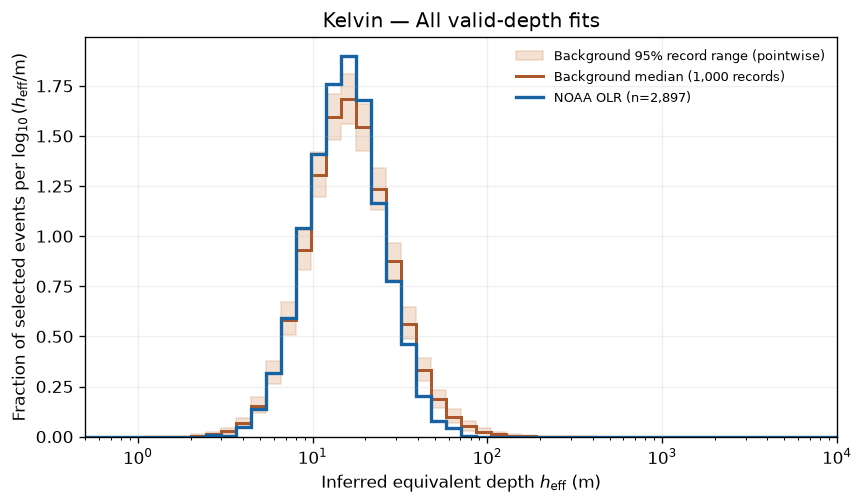

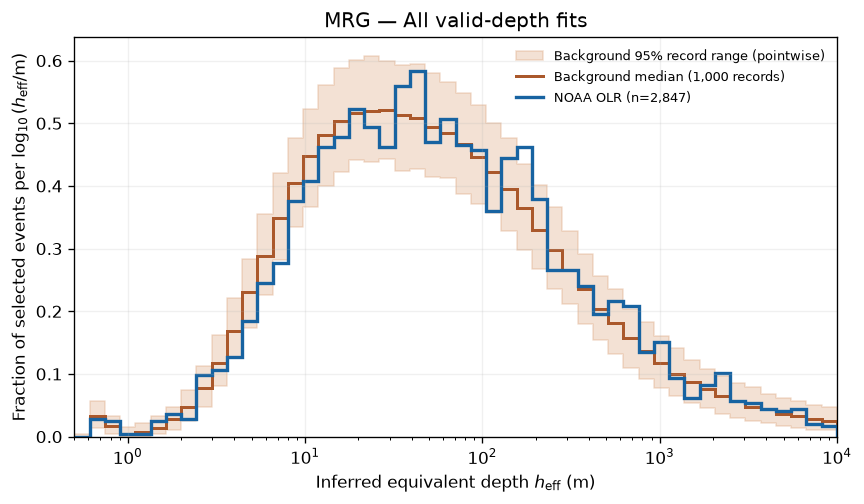

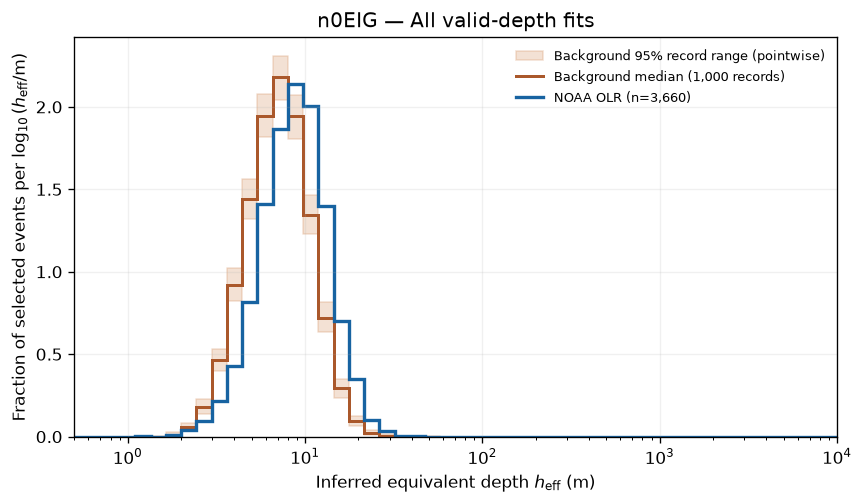

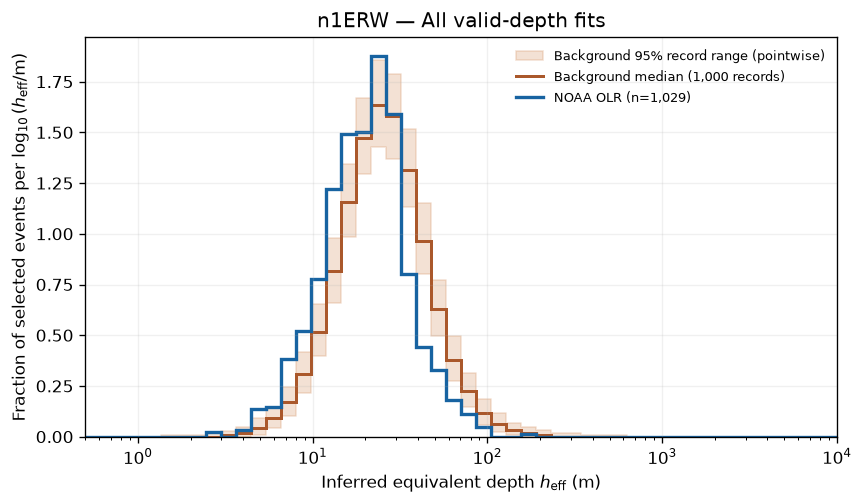

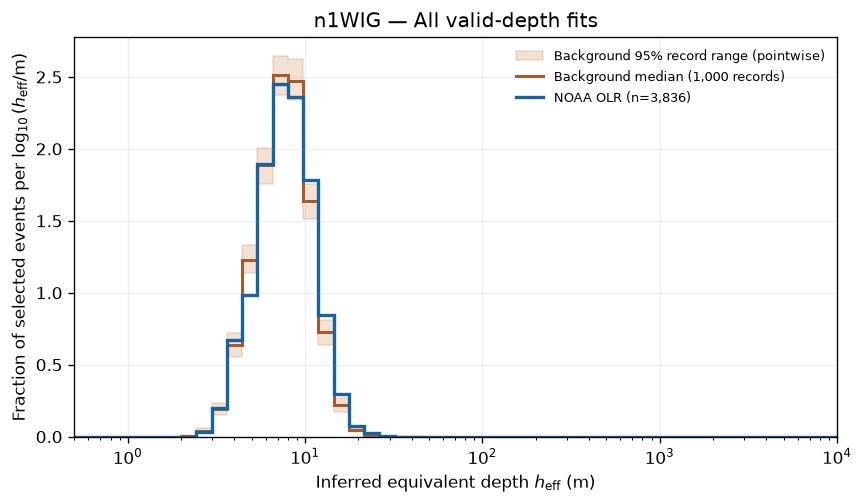

In [4]:
for wave in WAVES:
    plot_depth_distribution(wave, "relaxed")


## Linear detail: quality-screened depths, 1–200 m

The following five standalone panels use 1 m bins with a linear depth axis. Each bin shows its fraction of **all** selected events in the 21-year record, so depths outside 1–200 m are not renormalized away. The background band remains pointwise across 1,000 whole-record realizations.


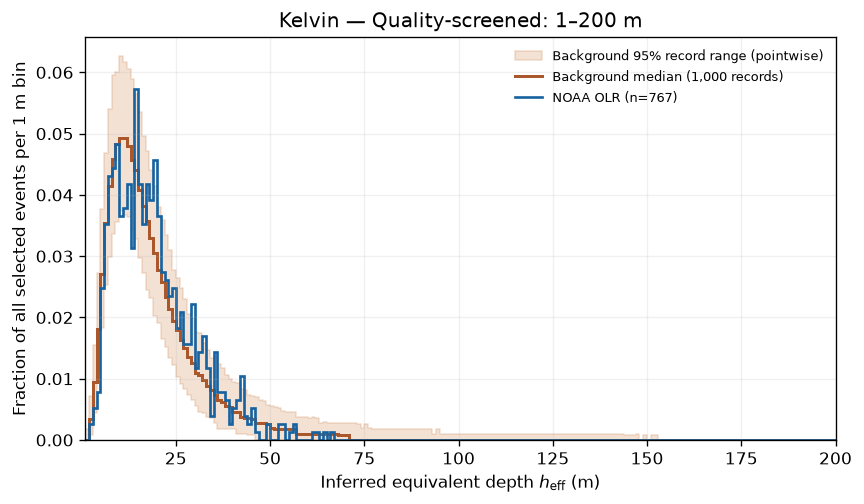

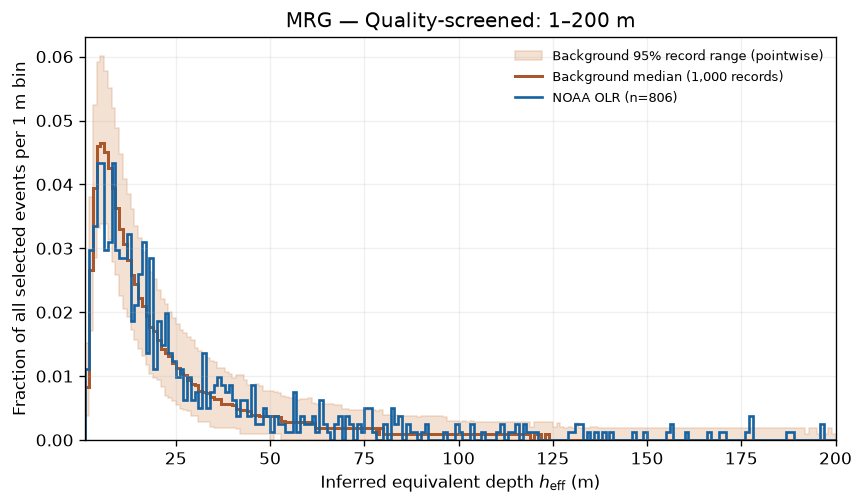

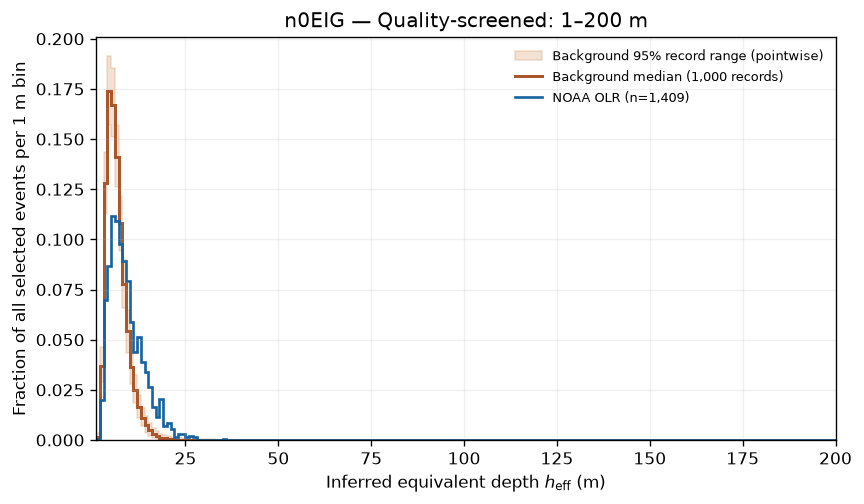

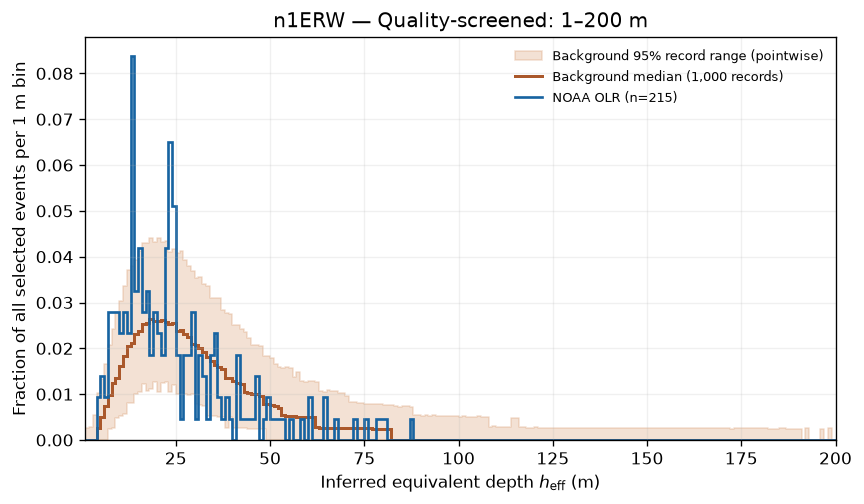

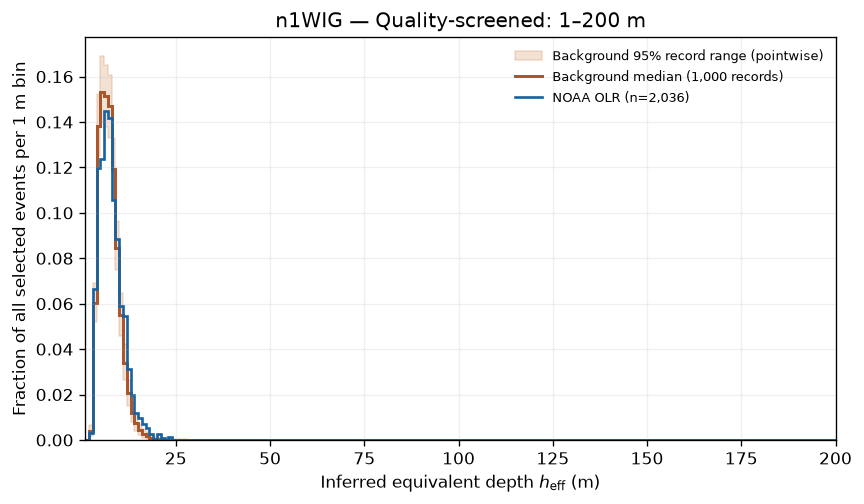

In [5]:
def plot_linear_depth_distribution(wave, selection):
    """Display one 1 m-bin depth comparison on 1–200 m; save no file."""
    result = results[wave][selection]
    observed_fraction = result["observed_linear_hist"] / result["observed_n"]
    null_fraction = result["null_linear_hist"] / result["null_n"][:, None]
    lower, median, upper = np.quantile(null_fraction, [0.025, 0.5, 0.975], axis=0)

    fig, ax = plt.subplots(figsize=(7.3, 4.3), dpi=120)
    ax.fill_between(LINEAR_EDGES_M, np.r_[lower, lower[-1]],
                    np.r_[upper, upper[-1]], step="post", color="#d28b57", alpha=0.25,
                    label="Background 95% record range (pointwise)")
    ax.stairs(median, LINEAR_EDGES_M, color="#aa582b", linewidth=1.8,
              label="Background median (1,000 records)")
    ax.stairs(observed_fraction, LINEAR_EDGES_M, color="#1763a1", linewidth=1.6,
              label=f"NOAA OLR (n={result['observed_n']:,})")
    ax.set(xlim=(1, 200), ylim=(0, None),
           xlabel=r"Inferred equivalent depth $h_{\mathrm{eff}}$ (m)",
           ylabel="Fraction of all selected events per 1 m bin",
           title=f"{wave} — {SELECTIONS[selection]}: 1–200 m")
    ax.grid(alpha=0.18)
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


for wave in WAVES:
    plot_linear_depth_distribution(wave, "screened")


## Linear detail: all valid-depth fits, 1–200 m

These panels use the same bins but omit the R², search-edge and cycle-count screens. A successful fit and a positive, dispersion-valid depth are still required.


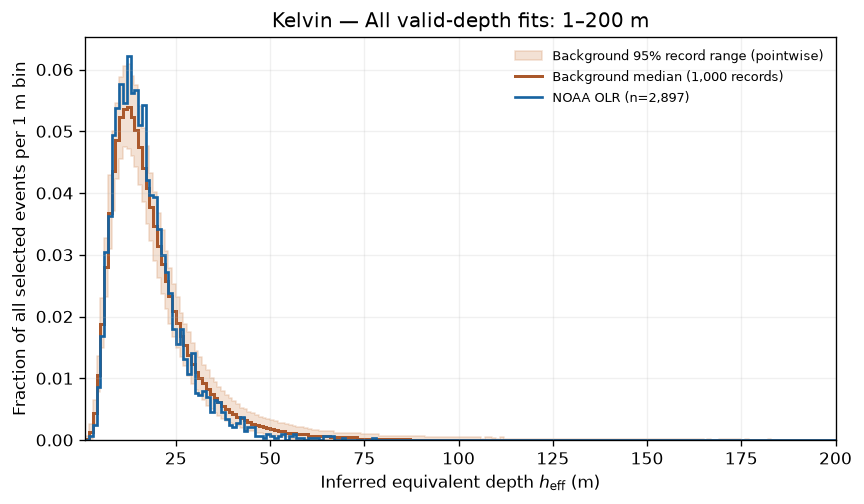

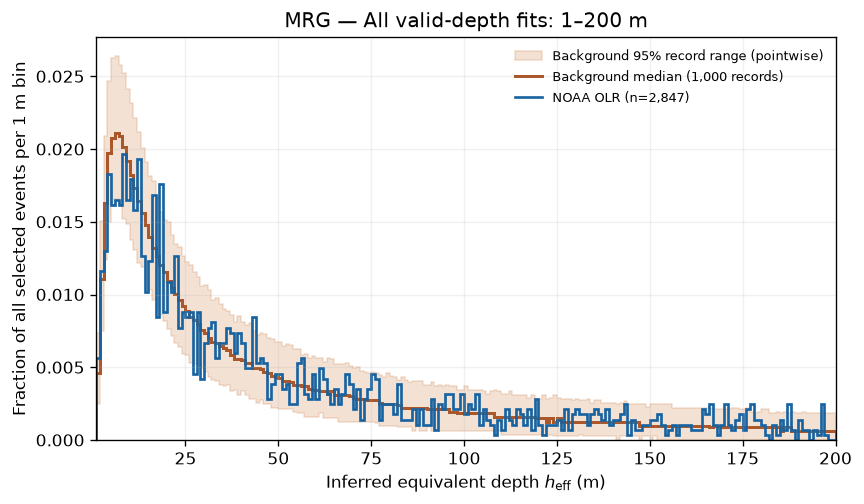

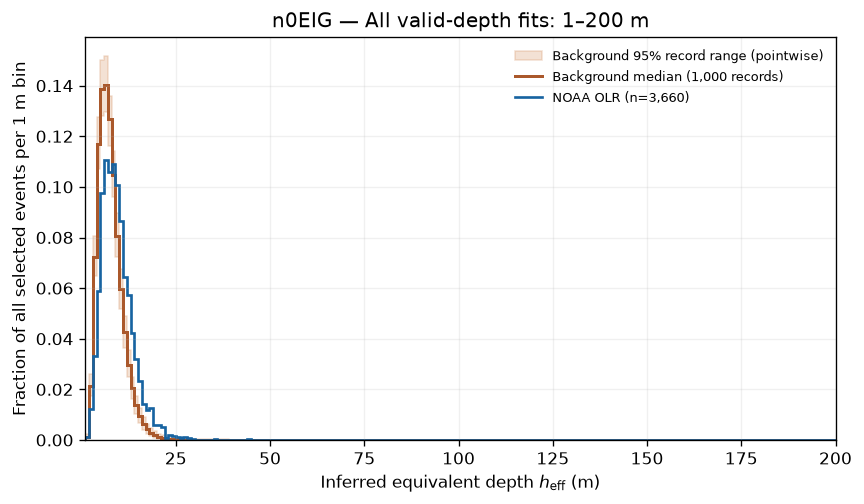

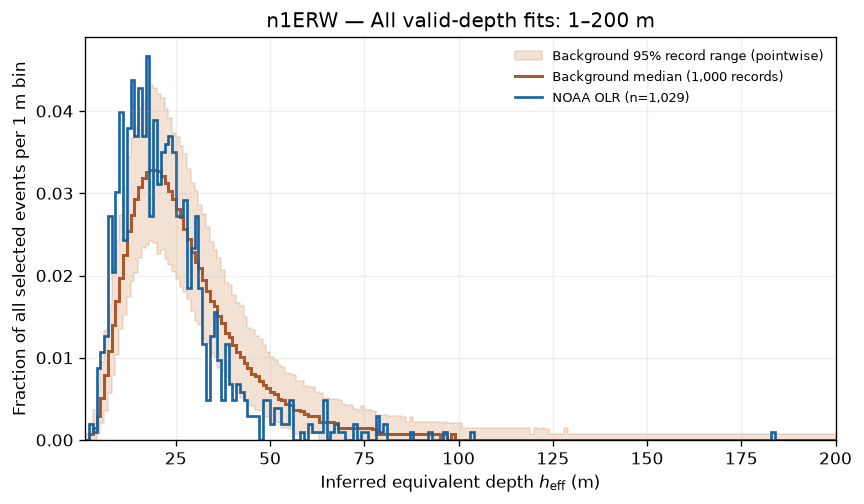

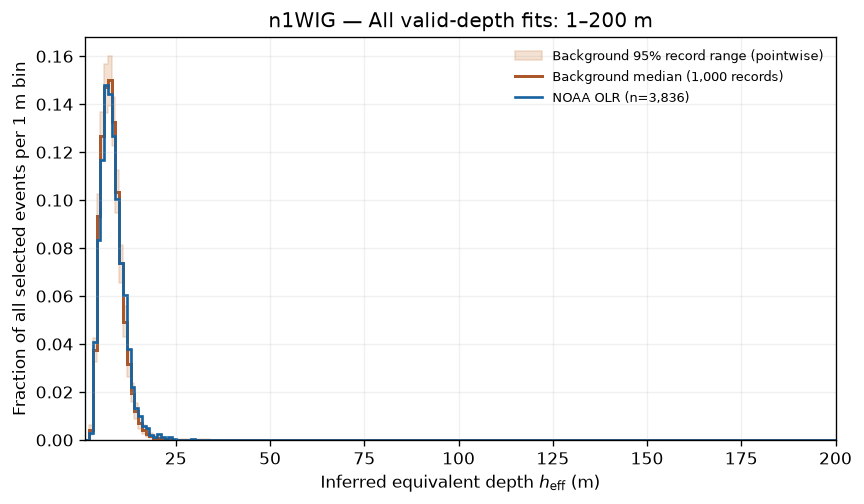

In [6]:
for wave in WAVES:
    plot_linear_depth_distribution(wave, "relaxed")


## MRG high-depth tail

The table counts observed MRG fits above 1,000 m directly from the catalog; the overview's log axis can visually exaggerate how many events occupy the long tail. The current MRG filter has rectangular wavenumber–frequency bounds and **no equivalent-depth restriction**. The Wheeler–Kiladis notebook draws 1, 10, 100 and 200 m curves as references, not as enforced fit limits.

For MRG, the resting-wave inversion is $c_0=\omega^2/(\beta+k\omega)$ and $h_{\mathrm{eff}}=c_0^2/g$. When the positive denominator is small, a small shift in fitted wavenumber or frequency produces a very large depth. Such extreme inversions need sensitivity checks before physical interpretation, even if a sinusoid fits well.


In [7]:
mrg_depths, _ = selected_depths(observed_catalogs["MRG"][0])
mrg_rows = []
for selection, depths in mrg_depths.items():
    mrg_rows.append({
        "selection": selection,
        "valid_depth_events": len(depths),
        "median_m": float(np.median(depths)),
        "1_to_200_m": int(np.count_nonzero((depths >= 1) & (depths <= 200))),
        "at_least_1000_m": int(np.count_nonzero(depths >= 1000)),
        "at_least_1000_pct": 100 * np.mean(depths >= 1000),
    })
display(pd.DataFrame(mrg_rows).round({"median_m": 2, "at_least_1000_pct": 2}))

mrg_fit = pd.read_csv(observed_catalogs["MRG"][0], usecols=[
    "h_eff_m", "fit_success", "dispersion_valid", "keep_for_histogram",
    "weighted_r2", "temporal_cycles",
])
large = (mrg_fit.fit_success & mrg_fit.dispersion_valid
         & np.isfinite(mrg_fit.h_eff_m) & (mrg_fit.h_eff_m >= 1000))
print(f"Among {large.sum()} valid MRG fits at or above 1,000 m: "
      f"{(large & mrg_fit.keep_for_histogram).sum()} pass quality; "
      f"{(large & (mrg_fit.temporal_cycles < 1)).sum()} fail the temporal-cycle screen; "
      f"{(large & (mrg_fit.weighted_r2 < 0.3)).sum()} fall below the R² cutoff.")


,selection,valid_depth_events,median_m,1_to_200_m,at_least_1000_m,at_least_1000_pct
0,screened,806,18.32,757,9,1.12
1,relaxed,2847,54.02,2133,233,8.18


Among 233 valid MRG fits at or above 1,000 m: 9 pass quality; 224 fail the temporal-cycle screen; 0 fall below the R² cutoff.


## Spectral variance mapped to equivalent depth

This is the variance analogue of the event-count plots above. It uses the saved full-record `spectrum.symmetric.nc` and `spectrum.antisymmetric.nc` from the same NOAA calibration. The observed spectrum is the taper-corrected Fourier power of the projected NOAA OLR anomalies; the background is the **expected** WK99-style smoothed Gaussian power. For each wave family, physical positive-frequency Fourier cells inside its current rectangular wavenumber–frequency box are assigned an *apparent* depth using that family's resting-background dispersion relation. The cell and its real-field conjugate contribute twice the stored power.

Each 1 m bin on 1–200 m is divided by the **total power in both projected symmetric and antisymmetric fields** for that source. Thus the y-axis is a percent of total **projected equatorial OLR spectral variance**, not a conditional distribution within one wave box. The table also gives the fraction inside 12–50 m and the fraction in the full box; it shows how much is omitted by the displayed depth range. This is the comparable total available for both observed OLR and the projected Gaussian background; it is not the variance of the unprojected latitude–longitude OLR field.

This spectral calculation does not apply the 1.5σ event detector or any fit-quality screen. A Fourier cell can contain wave and background contributions. Assigning a depth from its coordinates does **not** identify an individual wave event or measure that event's variance. The orange curve is a smooth expected background, not a realization percentile band, so differences here are descriptive rather than significance tests.


In [8]:
import xarray as xr

# Current rectangular analysis boxes: signed global wavenumber K and positive f (cycles/day).
# These are the BOX_PROFILES used to filter the fitted-event catalogs.
SPECTRAL_BOXES = {
    "Kelvin": ("symmetric", 1, 15, 1 / 14, 1 / 2.5),
    "n1ERW": ("symmetric", -15, -1, 1 / 90, 1 / 10),
    "MRG": ("antisymmetric", -10, -0.25, 1 / 10, 1 / 2.25),
    "n0EIG": ("antisymmetric", 0.25, 14, 1 / 6, 1 / 2.25),
    "n1WIG": ("symmetric", -15, -1, 1 / 4, 1 / 2),
}

spectra = {}
for symmetry in ("symmetric", "antisymmetric"):
    path = NULL_RUN / f"spectrum.{symmetry}.nc"
    with xr.open_dataset(path) as dataset:
        if set(dataset.data_vars) != {"background_power", "observed_taper_corrected_power"}:
            raise RuntimeError(f"Unexpected saved spectrum variables: {path}")
        frequencies = dataset.fft_frequency.to_numpy()
        wavenumbers = dataset.fft_wavenumber.to_numpy()
        if spectra and (not np.array_equal(frequencies, spectra["symmetric"]["frequencies"])
                        or not np.array_equal(wavenumbers, spectra["symmetric"]["wavenumbers"])):
            raise RuntimeError("Symmetric and antisymmetric FFT grids differ")
        observed_power = dataset.observed_taper_corrected_power.to_numpy()
        background_power = dataset.background_power.to_numpy()
        for power in (observed_power, background_power):
            if power.shape != (len(frequencies), len(wavenumbers)) or not np.isfinite(power).all() or (power < 0).any():
                raise RuntimeError(f"Invalid saved spectral power: {path}")
        spectra[symmetry] = dict(frequencies=frequencies, wavenumbers=wavenumbers,
                                 observed=observed_power, background=background_power)
if not np.array_equal(spectra["symmetric"]["background"], spectra["antisymmetric"]["background"]):
    raise RuntimeError("Expected a common pooled Gaussian background for both symmetries")

spectral_totals = {source: sum(spectra[symmetry][source].sum()
                               for symmetry in spectra)
                   for source in ("observed", "background")}
for source, total in spectral_totals.items():
    if total <= 0:
        raise RuntimeError(f"Nonpositive total projected spectral power: {source}")
print("Total projected spectral variance (W² m⁻⁴):",
      {source: float(round(total / observed_power.size, 2))
       for source, total in spectral_totals.items()})


Total projected spectral variance (W² m⁻⁴): {'observed': 318.06, 'background': 266.17}


In [9]:
EARTH_RADIUS_M = 6_371_008.0
GRAVITY_M_S2 = 9.80665
BETA_S_INV_M_INV = 2 * 7.292e-5 / EARTH_RADIUS_M


def spectral_equivalent_depth(wave, zonal_wavenumber, frequency_cpd):
    """Resting-branch h (m) on a (positive frequency, signed global K) FFT grid."""
    k = zonal_wavenumber / EARTH_RADIUS_M
    omega = 2 * np.pi * frequency_cpd / 86_400.0
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        if wave == "Kelvin":
            c0 = omega / k
        elif wave in ("MRG", "n0EIG"):
            denominator = BETA_S_INV_M_INV + k * omega
            c0 = np.where(denominator > 0, omega**2 / denominator, np.nan)
        else:
            coefficient = k**2 + BETA_S_INV_M_INV * k / omega
            discriminant = (3 * BETA_S_INV_M_INV)**2 + 4 * coefficient * omega**2
            if wave == "n1WIG":
                c0 = np.where(discriminant >= 0,
                              2 * omega**2 / (3 * BETA_S_INV_M_INV + np.sqrt(discriminant)),
                              np.nan)
            elif wave == "n1ERW":
                c0 = np.where((coefficient < 0) & (discriminant >= 0),
                              (-3 * BETA_S_INV_M_INV - np.sqrt(discriminant)) / (2 * coefficient),
                              np.nan)
            else:
                raise ValueError(f"Unknown wave family: {wave}")
        depth = c0**2 / GRAVITY_M_S2
    return np.where(np.isfinite(depth) & (depth > 0), depth, np.nan)


spectral_variance = {}
spectral_summary = []
for wave in WAVES:
    symmetry, k_min, k_max, f_min, f_max = SPECTRAL_BOXES[wave]
    spectrum = spectra[symmetry]
    # For q ~ cos(K*longitude - 2*pi*f*time), positive physical f occupies
    # negative temporal NumPy FFT frequencies at the same signed K.
    frequency_indices = np.flatnonzero((spectrum["frequencies"] < 0)
                                       & (-spectrum["frequencies"] >= f_min)
                                       & (-spectrum["frequencies"] <= f_max))
    wavenumber_indices = np.flatnonzero((spectrum["wavenumbers"] >= k_min)
                                        & (spectrum["wavenumbers"] <= k_max))
    if not len(frequency_indices) or not len(wavenumber_indices):
        raise RuntimeError(f"No Fourier cells inside {wave} box")
    physical_frequency = -spectrum["frequencies"][frequency_indices, None]
    signed_k = spectrum["wavenumbers"][None, wavenumber_indices]
    depth = spectral_equivalent_depth(wave, signed_k, physical_frequency)
    valid = np.isfinite(depth)
    spectral_variance[wave] = {}
    for source in ("observed", "background"):
        # Each selected cell has a conjugate of equal power in the real field.
        power = 2 * spectrum[source][np.ix_(frequency_indices, wavenumber_indices)]
        histogram = np.histogram(depth[valid], bins=LINEAR_EDGES_M,
                                 weights=power[valid])[0]
        total = spectral_totals[source]
        in_range = valid & (depth >= 1) & (depth <= 200)
        if not np.isclose(histogram.sum(), power[in_range].sum(), rtol=1e-10):
            raise RuntimeError(f"Spectral histogram lost power: {wave}/{source}")
        spectral_variance[wave][source] = 100 * histogram / total
        spectral_summary.append(dict(
            wave_type=wave, source=source,
            full_box_pct=100 * power.sum() / total,
            valid_depth_pct=100 * power[valid].sum() / total,
            one_to_200_m_pct=100 * histogram.sum() / total,
            twelve_to_50_m_pct=100 * power[valid & (depth >= 12) & (depth < 50)].sum() / total,
        ))

spectral_table = pd.DataFrame(spectral_summary)
display(spectral_table.round(3))

# The plots use a separate total-variance denominator for each source. These
# integrated ratios instead compare the observed and background power directly.
paired = spectral_table.pivot(index="wave_type", columns="source",
                              values=["full_box_pct", "twelve_to_50_m_pct"])
absolute_scale = spectral_totals["observed"] / spectral_totals["background"]
power_ratios = pd.DataFrame(index=WAVES)
for column, label in (("full_box_pct", "full_box_observed_to_background"),
                      ("twelve_to_50_m_pct", "12_to_50_m_observed_to_background")):
    power_ratios[label] = absolute_scale * paired[column]["observed"] / paired[column]["background"]
power_ratios.index.name = "wave_type"
display(power_ratios.round(3))


,wave_type,source,full_box_pct,valid_depth_pct,one_to_200_m_pct,twelve_to_50_m_pct
0,Kelvin,observed,9.193,9.193,8.868,4.258
1,Kelvin,background,9.497,9.497,8.501,3.228
2,MRG,observed,4.045,3.675,3.083,0.960
3,MRG,background,5.222,4.706,3.902,1.003
4,n0EIG,observed,2.884,2.884,2.879,0.971
5,n0EIG,background,3.957,3.957,3.950,0.835
6,n1ERW,observed,11.523,11.523,10.437,4.264
7,n1ERW,background,10.941,10.941,9.166,3.539
8,n1WIG,observed,1.214,1.214,1.214,0.294
9,n1WIG,background,1.571,1.571,1.571,0.346


,full_box_observed_to_background,12_to_50_m_observed_to_background
wave_type,,
Kelvin,1.157,1.576
MRG,0.926,1.144
n0EIG,0.871,1.390
n1ERW,1.259,1.440
n1WIG,0.923,1.014


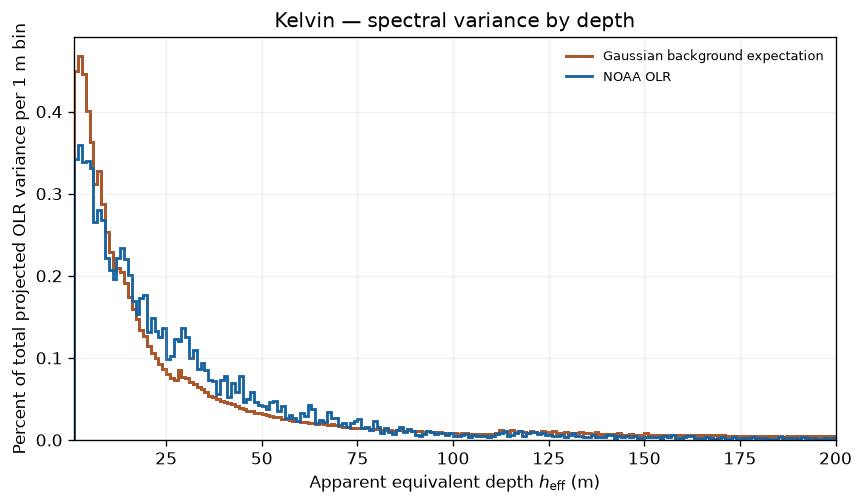

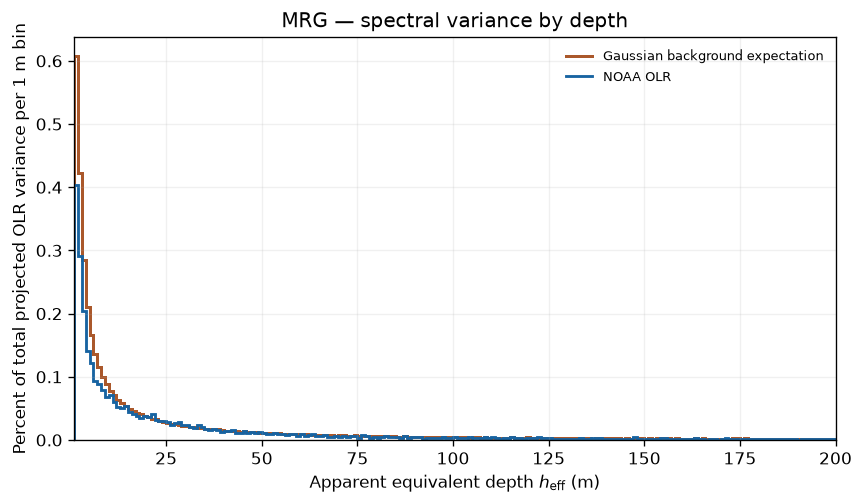

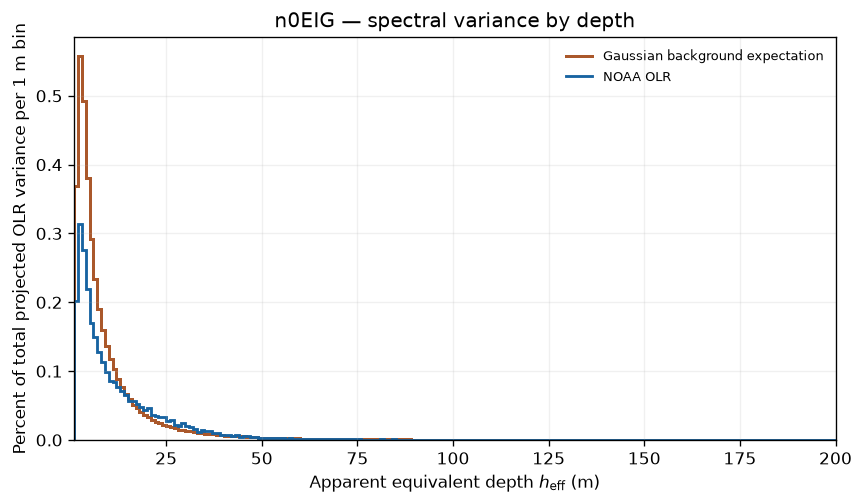

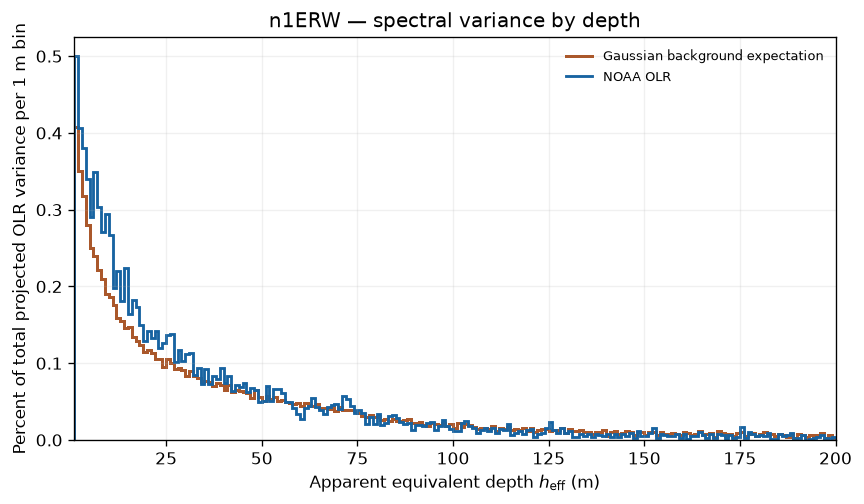

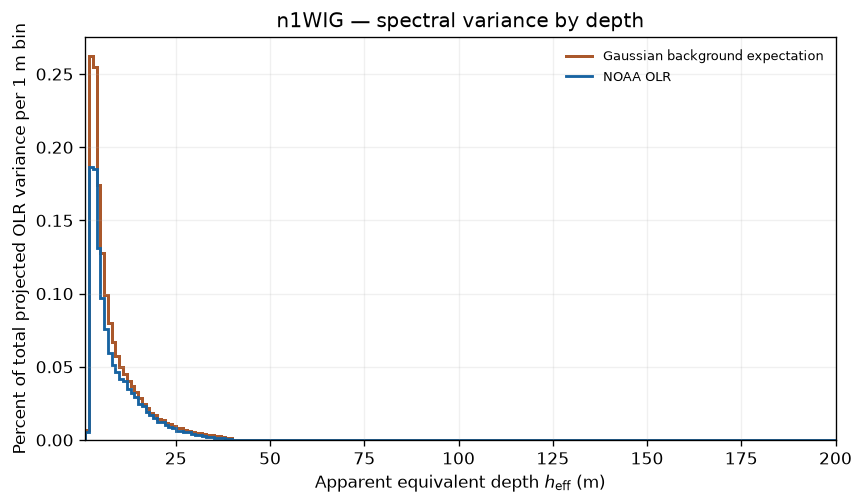

In [10]:
for wave in WAVES:
    fig, ax = plt.subplots(figsize=(7.3, 4.3), dpi=120)
    ax.stairs(spectral_variance[wave]["background"], LINEAR_EDGES_M,
              color="#aa582b", linewidth=1.8, label="Gaussian background expectation")
    ax.stairs(spectral_variance[wave]["observed"], LINEAR_EDGES_M,
              color="#1763a1", linewidth=1.7, label="NOAA OLR")
    ax.set(xlim=(1, 200), ylim=(0, None),
           xlabel=r"Apparent equivalent depth $h_{\mathrm{eff}}$ (m)",
           ylabel="Percent of total projected OLR variance per 1 m bin",
           title=f"{wave} — spectral variance by depth")
    ax.grid(alpha=0.18)
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


The table separates three quantities: all spectral power in a wave's rectangular box, the subset with a valid resting-branch depth, and the subset plotted at 1–200 m. The 12–50 m column is a descriptive reference to the range emphasized by Wheeler and Kiladis (1999), not a fitted confidence interval. Unlike the earlier event-count plots, these curves retain differences in spectral power concentration relative to the total projected variance. The second table restores the absolute observed/background power ratio after accounting for the separate denominators; it is closer to a Wheeler–Kiladis power comparison. They still require a calibrated test against null spectral realizations and smoothing choices before any excess can be called statistically significant.


## Interpretation and limits

Across all five wave types, NOAA has fewer selected depth events than the median of the 1,000 Gaussian records under both quality selections (see the count table). This is a comparison of event counts; the density panels compare **distribution shapes after within-record normalization**. The count difference alone does not establish that any depth range is preferred.

A concentration in the observed curve must be judged against the **empirical** background curve, which need not be flat: filters, search boxes, fit geometry, dispersion inversion, and selection rules can themselves produce preferred fitted depths. The plotted percentile bands are pointwise descriptions of complete null records. Searching many depths and five wave types requires a separate global or multiplicity-aware test before calling any feature statistically significant. The background model is stationary Gaussian and may miss non-Gaussian tails or local/seasonal variability. These are fitted equivalent depths under the project's zero-background-wind dispersion assumptions, not direct measurements of vertical mode depth.

No figures are saved outside this notebook.
